<a href="https://colab.research.google.com/github/velasquezcalderonrafael32-git/Proyecto-Final-Programacion-Rafael-Velasquez-y-Juan-Martin-Franco/blob/Rama-JM/Proyecto_Final_Programaci%C3%B3n_Rafael_Velasquez_y_Juan_Martin_Franco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

JUAN MARTIN FRANCO - RAFAEL VELASQUEZ

---



In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

datos_panaderia = pd.ExcelFile("datos_panaderia.xlsx")

productos = pd.read_excel(datos_panaderia, sheet_name="Productos").dropna(subset=["Categoría"])
zonas = pd.read_excel(datos_panaderia, sheet_name="Zonas").dropna(subset=["Distancia al negocio (km)"])
parametros = pd.read_excel(datos_panaderia, sheet_name="Parametros")
franjas = pd.read_excel(datos_panaderia, sheet_name="Franjas").dropna(subset=["Horario"])
pedidos = pd.read_excel(datos_panaderia, sheet_name="Pedidos").dropna(subset=["Zona"])
escenarios = pd.read_excel(datos_panaderia, sheet_name="Escenarios")
print(len(productos), "productos |", len(zonas), "zonas |", len(pedidos), "pedidos |", len(escenarios), "escenarios")

10 productos | 8 zonas | 80 pedidos | 6 escenarios


In [22]:
valores = parametros["Valor"].tolist()
p = {
    "costo_km":   valores[0],
    "pago_hora":  valores[1],
    "empaque":    valores[2],
    "comision":   valores[3],
    "n_rep":      int(valores[4]),
    "prep":       valores[6],
    "espera_max": valores[7],
    "margen":     valores[8],
}
print(p)

tiempo_zona = dict(zip(zonas["Zona (barrio)"], zonas["Tiempo ida y vuelta (min)"]))
dist_zona   = dict(zip(zonas["Zona (barrio)"], zonas["Distancia al negocio (km)"]))

{'costo_km': 700.0, 'pago_hora': 12000.0, 'empaque': 800.0, 'comision': 0.0, 'n_rep': 2, 'prep': 12.0, 'espera_max': 45.0, 'margen': 0.62}


In [25]:
def costo_reparto(distancia_km, tiempo_min, valor, p):
    #Costo de entregar un pedido (en COP)
    km = distancia_km * 2 * p["costo_km"]            # ida y vuelta
    mano_obra = tiempo_min / 60 * p["pago_hora"]
    comision = valor * p["comision"]
    return km + mano_obra + p["empaque"] + comision


def ganancia_pedido(valor, tarifa, costo, p):
    #Margen de los productos + tarifa cobrada - costo de reparto.
    return valor * p["margen"] + tarifa - costo


# Se calcula el costo de reparto y la ganancia de cada pedido usando las funciones definidas arriba
costos, ganancias = [], []
for _, fila in pedidos.iterrows():
    zona = fila["Zona"]
    c = costo_reparto(dist_zona[zona], tiempo_zona[zona], fila["Valor productos (COP)"], p)
    g = ganancia_pedido(fila["Valor productos (COP)"], fila["Tarifa cobrada (COP)"], c, p)
    costos.append(c)
    ganancias.append(g)

pedidos["Costo reparto"] = costos
pedidos["Ganancia"] = ganancias
pedidos["Rentable"] = pedidos["Ganancia"] > 0

print("Pedidos rentables:", (pedidos['Rentable']).sum(), "de", len(pedidos))
pedidos.head()

Pedidos rentables: 60 de 80


,ID pedido,Día,Franja,Zona,N.º productos,Valor productos (COP),Distancia (km),Tarifa cobrada (COP),Costo reparto,Ganancia,Rentable
0,P001,Sábado,Mañana,Chapinero Central,1.0,5500.0,2.5,3500.0,9100.0,-2190.0,False
1,P002,Martes,Noche,Teusaquillo,1.0,116000.0,4.0,4500.0,13200.0,63220.0,True
2,P003,Sábado,Mediodía,Chapinero Alto,2.0,18800.0,1.5,3000.0,6500.0,8156.0,True
3,P004,Domingo,Mediodía,Teusaquillo,1.0,3000.0,4.0,4500.0,13200.0,-6840.0,False
4,P005,Miércoles,Mañana,Chapinero Alto,5.0,42300.0,1.5,3000.0,6500.0,22726.0,True


In [55]:
def redondear_arriba(x, paso=500):
    return int(np.ceil(x / paso) * paso)

AUMENTO_TARIFA = 2000          # aumento máximo de tarifa en zonas rentables
AUMENTO_TARIFA_PERDIDA = 4000  # aumento máximo en zonas que pierden dinero
PEDIDO_MIN_MAX = 20000         # techo del pedido mínimo

resumen = pedidos.groupby("Zona").agg(
    pedidos=("ID pedido", "count"),
    valor_prom=("Valor productos (COP)", "mean"),
    tarifa_actual=("Tarifa cobrada (COP)", "mean"),
    costo_prom=("Costo reparto", "mean"),
    ganancia_total=("Ganancia", "sum"),
    ganancia_prom=("Ganancia", "mean"),
).reset_index()

sug_tarifa, sug_minimo = [], []
for _, f in resumen.iterrows():
    # Tarifa: cubrir el costo, subiendo solo un tramo y sin bajar nunca la actual
    aumento = AUMENTO_TARIFA_PERDIDA if f["ganancia_prom"] < 0 else AUMENTO_TARIFA
    tarifa = redondear_arriba(min(f["costo_prom"], f["tarifa_actual"] + aumento))
    tarifa = max(tarifa, redondear_arriba(f["tarifa_actual"]))
    sug_tarifa.append(tarifa)

    # Pedido mínimo: valor con el que el margen cubre lo que la tarifa no alcanza a pagar
    faltante = f["costo_prom"] - tarifa
    if faltante > 0:
        pedido_min = min(redondear_arriba(faltante / p["margen"], 1000), PEDIDO_MIN_MAX)
    else:
        pedido_min = 0
    sug_minimo.append(pedido_min)

resumen["tarifa_sugerida"] = sug_tarifa
resumen["pedido_min_sugerido"] = sug_minimo

# --- Simulación ---
# Ningún pedido se pierde: los que quedan por debajo del mínimo se cuentan por el valor del mínimo
sim = pedidos.merge(resumen[["Zona", "tarifa_sugerida", "pedido_min_sugerido"]], on="Zona")
sim["Valor sim"] = np.maximum(sim["Valor productos (COP)"], sim["pedido_min_sugerido"])
sim["Ganancia sim"] = (sim["Valor sim"] * p["margen"]
                       + sim["tarifa_sugerida"]
                       - sim["Costo reparto"])

resumen["ganancia_total_sim"] = resumen["Zona"].map(sim.groupby("Zona")["Ganancia sim"].sum())
resumen["ganancia_prom_sim"] = resumen["Zona"].map(sim.groupby("Zona")["Ganancia sim"].mean())

resumen = resumen.sort_values("ganancia_prom").round(0)

tabla1 = resumen[["Zona", "pedidos", "valor_prom", "tarifa_actual", "costo_prom",
                  "ganancia_total", "ganancia_prom", "tarifa_sugerida",
                  "pedido_min_sugerido", "ganancia_total_sim", "ganancia_prom_sim"]].copy()
tabla1.columns = ["Zona", "Pedidos", "Valor prom.", "Tarifa actual", "Costo reparto prom.",
                  "Ganancia total", "Ganancia prom.", "Tarifa sugerida",
                  "Pedido mín. sugerido", "Ganancia total simulada", "Ganancia prom. simulada"]

tabla1

,Zona,Pedidos,Valor prom.,Tarifa actual,Costo reparto prom.,Ganancia total,Ganancia prom.,Tarifa sugerida,Pedido mín. sugerido,Ganancia total simulada,Ganancia prom. simulada
7,Usaquén,8,14325.0,7000.0,23000.0,-56948.0,-7118.0,11000,20000,17770.0,2221.0
0,Cedritos,3,43600.0,9000.0,30200.0,17496.0,5832.0,11000,20000,26100.0,8700.0
5,Suba,6,62433.0,11000.0,37400.0,73852.0,12309.0,13000,20000,90626.0,15104.0
6,Teusaquillo,10,48190.0,4500.0,13200.0,211778.0,21178.0,6500,11000,243372.0,24337.0
1,Chapinero Alto,20,41945.0,3000.0,6500.0,450118.0,22506.0,5000,3000,490242.0,24512.0
2,Chapinero Central,16,48106.0,3500.0,9100.0,387614.0,24226.0,5500,6000,421164.0,26323.0
4,Rosales,9,58833.0,4000.0,10600.0,268890.0,29877.0,6000,8000,288254.0,32028.0
3,Chicó,8,83938.0,5000.0,15800.0,329930.0,41241.0,7000,15000,347170.0,43396.0


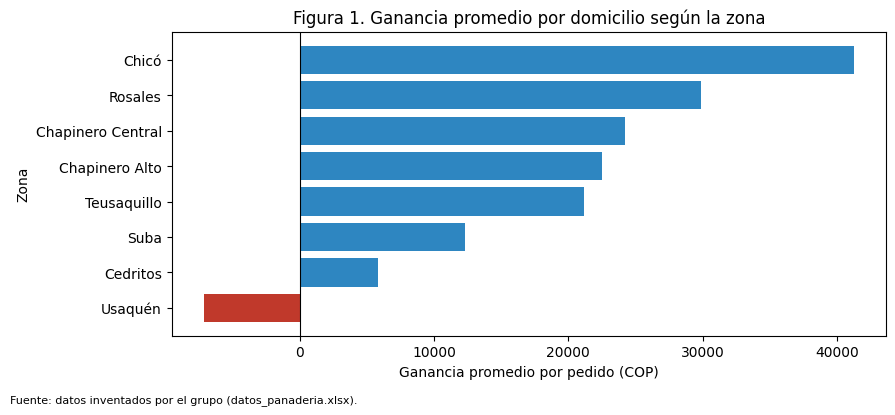

In [57]:
# Figura 1: ganancia promedio por pedido según la zona
colores = ["#C0392B" if g < 0 else "#2E86C1" for g in resumen["ganancia_prom"]]
plt.figure(figsize=(9, 4))
plt.barh(resumen["Zona"], resumen["ganancia_prom"], color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Figura 1. Ganancia promedio por domicilio según la zona")
plt.xlabel("Ganancia promedio por pedido (COP)")
plt.ylabel("Zona")
plt.figtext(0.01, -0.02, "Fuente: datos inventados por el grupo (datos_panaderia.xlsx).", fontsize=8)
plt.tight_layout()
plt.show()

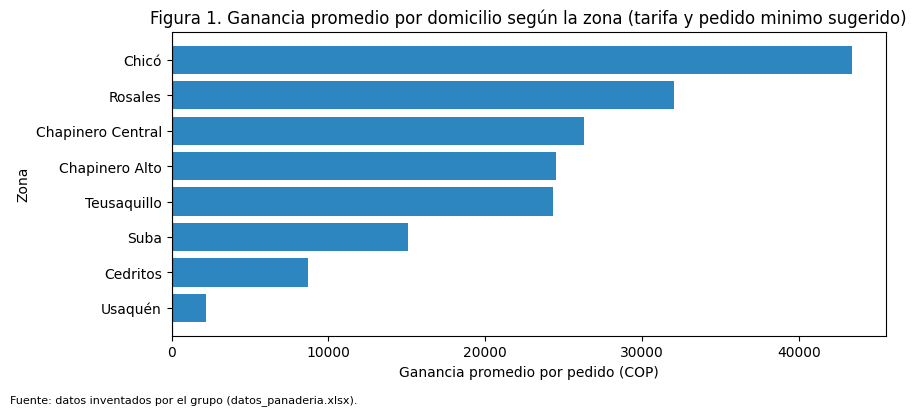

In [60]:
colores = ["#C0392B" if g < 0 else "#2E86C1" for g in tabla1["Ganancia prom. simulada"]]
plt.figure(figsize=(9, 4))
plt.barh(tabla1["Zona"], tabla1["Ganancia prom. simulada"], color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Figura 1. Ganancia promedio por domicilio según la zona (tarifa y pedido minimo sugerido)")
plt.xlabel("Ganancia promedio por pedido (COP)")
plt.ylabel("Zona")
plt.figtext(0.01, -0.02, "Fuente: datos inventados por el grupo (datos_panaderia.xlsx).", fontsize=8)
plt.tight_layout()
plt.show()

In [41]:
nombres_zona = list(zonas["Zona (barrio)"])
prob_zona = np.array(zonas["% de pedidos"], dtype=float)
prob_zona = prob_zona / prob_zona.sum()


def simular_franja(n_pedidos, duracion_h, n_rep, rng, p):
    """Devuelve (zonas de los pedidos atendidos, tardíos, pendientes)."""
    minutos = duracion_h * 60
    llegadas = np.sort(rng.uniform(0, minutos, n_pedidos))
    libres = [0.0] * n_rep                       # minuto en que se desocupa cada repartidor
    atendidos, tardios, pendientes = [], 0, 0

    for llegada in llegadas:
        zona = rng.choice(nombres_zona, p=prob_zona)
        t_total = tiempo_zona[zona]
        i = libres.index(min(libres))            # repartidor que se desocupa primero
        inicio = max(llegada + p["prep"], libres[i])
        if inicio > minutos:                     # no alcanza a salir en la franja
            pendientes += 1
            continue
        libres[i] = inicio + t_total
        atendidos.append(zona)
        if (inicio + t_total / 2) - llegada > p["espera_max"]:
            tardios += 1
    return atendidos, tardios, pendientes


# Ejemplo: día normal, 2 repartidores, una simulación por franja
rng = np.random.default_rng(1)
filas = []
for _, fr in franjas.iterrows():
    at, tard, pend = simular_franja(int(fr["Pedidos esperados (día normal)"]),
                                    fr["Duración (horas)"], p["n_rep"], rng, p)
    filas.append([fr["Franja"], int(fr["Pedidos esperados (día normal)"]), len(at), tard, pend])

pd.DataFrame(filas, columns=["Franja", "Pedidos que llegan", "Atendidos", "Tardíos", "Pendientes"])

,Franja,Pedidos que llegan,Atendidos,Tardíos,Pendientes
0,Mañana,14,11,3,3
1,Mediodía,8,7,1,1
2,Tarde,6,6,0,0
3,Noche,12,7,4,5


In [42]:
valores_pedidos = pedidos["Valor productos (COP)"].to_numpy()
valores_zona = {z: pedidos.loc[pedidos["Zona"] == z, "Valor productos (COP)"].to_numpy() for z in nombres_zona}
tarifa_zona = dict(zip(zonas["Zona (barrio)"], zonas["Tarifa de envío actual (COP)"]))


def simular_dia(esc, rng, p):
    """Simula un día completo para un escenario y devuelve sus resultados."""
    n_rep = int(esc["Repartidores"])
    ingresos = costos_var = 0.0
    llegan = atendidos_tot = tardios_tot = pendientes_tot = rechazados = 0

    for _, fr in franjas.iterrows():
        n = int(round(fr["Pedidos esperados (día normal)"] * esc["Factor de demanda"]))
        llegan += n
        # El pedido mínimo: si el valor es menor, el cliente no pide
        n_efectivos = n
        if esc["Pedido mínimo (COP)"] > 0:
            n_efectivos = 0
            for _ in range(n):
                if rng.choice(valores_pedidos) >= esc["Pedido mínimo (COP)"]:
                    n_efectivos += 1
            rechazados += n - n_efectivos

        at, tard, pend = simular_franja(n_efectivos, fr["Duración (horas)"], n_rep, rng, p)
        atendidos_tot += len(at); tardios_tot += tard; pendientes_tot += pend

        for zona in at:
            valores_z = valores_zona[zona] if len(valores_zona[zona]) > 0 else valores_pedidos
            valor = rng.choice(valores_z)
            if esc["Pedido mínimo (COP)"] > 0:
                valor = max(valor, esc["Pedido mínimo (COP)"])
            tarifa = tarifa_zona[zona] * (1 + esc["Cambio en tarifa de envío (%)"])
            ingresos += valor * p["margen"] + tarifa
            costos_var += (dist_zona[zona] * 2 * p["costo_km"] + p["empaque"] + valor * p["comision"])

    horas_dia = franjas["Duración (horas)"].sum()
    costo_repartidores = n_rep * horas_dia * p["pago_hora"]
    return {
        "llegan": llegan, "atendidos": atendidos_tot, "tardíos": tardios_tot,
        "pendientes": pendientes_tot, "rechazados": rechazados,
        "ganancia": ingresos - costos_var - costo_repartidores,
    }


rng = np.random.default_rng(42)
N_DIAS = 200
filas = []
for _, esc in escenarios.iterrows():
    dias = [simular_dia(esc, rng, p) for _ in range(N_DIAS)]
    prom = pd.DataFrame(dias).mean()
    filas.append([esc["Escenario"], int(esc["Repartidores"]), prom["llegan"], prom["atendidos"],
                  prom["tardíos"], prom["pendientes"], prom["rechazados"], prom["ganancia"]])

comparacion = pd.DataFrame(filas, columns=["Escenario", "Repartidores", "Pedidos que llegan", "Atendidos",
                                          "Tardíos", "Pendientes", "Rechazados (pedido mín.)", "Ganancia diaria (COP)"]).round(1)
comparacion

,Escenario,Repartidores,Pedidos que llegan,Atendidos,Tardíos,Pendientes,Rechazados (pedido mín.),Ganancia diaria (COP)
0,Base,2,40.0,32.4,13.0,7.6,0.0,544866.2
1,Demanda alta,2,60.0,39.5,20.8,20.5,0.0,758833.8
2,Más repartidores,3,60.0,49.5,19.0,10.5,0.0,860062.0
3,Menos repartidores,1,40.0,21.0,13.2,19.0,0.0,395936.8
4,Tarifa +20%,2,40.0,32.2,12.9,7.8,0.0,570783.8
5,Pedido mínimo $25.000,2,40.0,20.1,4.9,1.9,18.0,260322.0


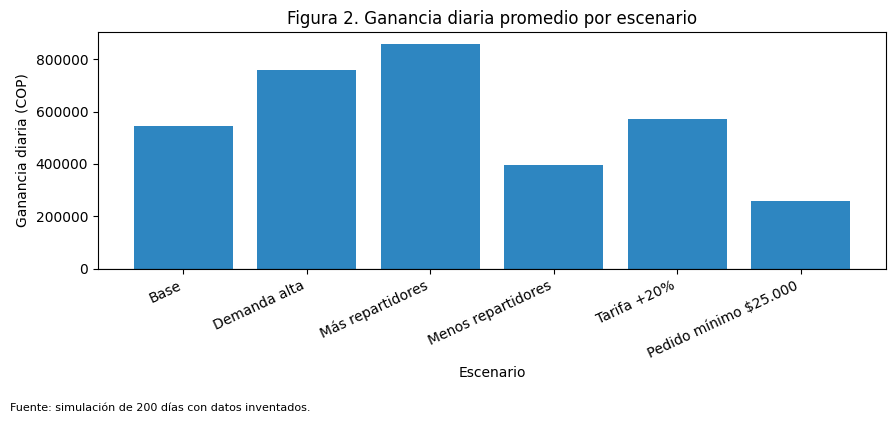

Escenario más rentable: Más repartidores con $860,062 diarios
  Pedidos tardíos: 19.0 | pendientes: 10.5


In [43]:
# Figura 2: ganancia diaria por escenario
colores = ["#C0392B" if g < 0 else "#2E86C1" for g in comparacion["Ganancia diaria (COP)"]]
plt.figure(figsize=(9, 4))
plt.bar(comparacion["Escenario"], comparacion["Ganancia diaria (COP)"], color=colores)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Figura 2. Ganancia diaria promedio por escenario")
plt.xlabel("Escenario")
plt.ylabel("Ganancia diaria (COP)")
plt.xticks(rotation=25, ha="right")
plt.figtext(0.01, -0.04, "Fuente: simulación de 200 días con datos inventados.", fontsize=8)
plt.tight_layout()
plt.show()

mejor = comparacion.loc[comparacion["Ganancia diaria (COP)"].idxmax()]
print(f"Escenario más rentable: {mejor['Escenario']} con ${mejor['Ganancia diaria (COP)']:,.0f} diarios")
print(f"  Pedidos tardíos: {mejor['Tardíos']} | pendientes: {mejor['Pendientes']}")

CONCLUSIONES/LIMITACIONES


CONCLUSIONES

Con los datos ficticios que armamos vimos que no todos los domicilios dejan ganancia: los barrios cercanos suelen salir bien, pero en los más lejanos el costo de enviar el pedido es mayor que la tarifa cobrada. En total, cantidad rentables de los total de pedidos fueron rentables, y las zonas con más pérdidas fueron zonas. Al subir un poco la tarifa de envío y poner un pedido mínimo en esas zonas, la ganancia promedio mejoró y dejó de ser negativa en zonas. En la simulación de días completos, el escenario más rentable fue escenario, con unos valores diarios, y notamos que tener más repartidores no siempre conviene, porque se pagan por todas las horas aunque no haya suficientes pedidos. Por eso, a la panadería le conviene cobrar el envío según la distancia, poner un pedido mínimo en las zonas lejanas y elegir bien cuántos repartidores tener según la demanda.

LIMITACIONES

Los datos son ficticios, así que los resultados no se pueden tomar como la realidad.
Usamos tiempos y distancias fijos por zona, pero en la vida real el tráfico o la lluvia los cambian.
Supusimos cómo reaccionan los clientes. Solo dejan de pedir si no llegan al mínimo, y no tuvimos en cuenta que se puedan ir a la competencia si suben la tarifa.
La simulación es sencilla. No consideramos que un repartidor lleve varios pedidos en un viaje, ni descansos o imprevistos.
Los repartidores se cobran distinto en dos partes del código: por tiempo de viaje en el análisis por pedido y por todas las horas en la simulación diaria, así que esas ganancias no son del todo comparables.
Los resultados cambian un poco en cada corrida por el azar, aunque repetimos 200 días para sacar un promedio.
No incluimos otros costos de la panadería, como arriendo o servicios.